<a href="https://colab.research.google.com/github/rifqiiiz/datascience-project/blob/main/03_model_design_advanced_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03B - Model Design & Optimization: Advanced ML Model **[M + O]**

**Judul Proyek:** Prediksi Tingkat Kepadatan Lalu Lintas Perkotaan Menggunakan Algoritma Klasifikasi Machine Learning dan Multilayer Perceptron (PyTorch) Berbasis Data Sensor Jalan Raya  
**Nama / NIM:** Muhammad Rifqi Maulana / 244311018, Vicky Rizkyanto / 244311030

**Program Studi:** D4 Teknologi Rekayasa Perangkat Lunak – Politeknik Negeri Madiun  
**Mata Kuliah:** Data Science (TRPL22406)  
**Model:** Model 2 – Advanced ML Model (*Random Forest Classifier* + Hyperparameter Tuning)

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

In [2]:
# 1. Memuat Data Hasil Preprocessing (Bebas Data Leakage dari Tahap L)
if os.path.exists("../data/processed/traffic_splits.npz"):
    data = np.load("../data/processed/traffic_splits.npz")
    X_train, y_train = data["X_train"], data["y_train"]
    X_val, y_val = data["X_val"], data["y_val"]
    preprocessor = joblib.load("../models/preprocessor.joblib")
    label_encoder = joblib.load("../models/label_encoder.joblib")
    feature_names = preprocessor.get_feature_names_out()
    class_names = label_encoder.classes_
else:
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
    from sklearn.compose import ColumnTransformer

    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"
    df = pd.read_csv(url, compression="gzip").drop_duplicates().reset_index(drop=True)
    df = df[df["temp"] > 200].reset_index(drop=True)
    df["holiday"] = df["holiday"].fillna("None")
    df["date_time"] = pd.to_datetime(df["date_time"])
    df["hour"] = df["date_time"].dt.hour
    df["day_of_week"] = df["date_time"].dt.dayofweek
    df["month"] = df["date_time"].dt.month
    df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
    df["is_rush_hour"] = ((df["is_weekend"] == 0) & (df["hour"].isin([7, 8, 9, 16, 17, 18]))).astype(int)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)
    df["target_label"] = df["traffic_volume"].apply(lambda v: "Lancar" if v < 2500 else ("Padat" if v < 5000 else "Macet"))

    num_cols = ["temp", "rain_1h", "snow_1h", "clouds_all", "hour_sin", "hour_cos", "day_of_week", "month", "is_weekend", "is_rush_hour"]
    cat_cols = ["holiday", "weather_main"]
    X = df[num_cols + cat_cols]
    le = LabelEncoder()
    y = le.fit_transform(df["target_label"])
    class_names = le.classes_

    X_temp, _, y_temp, _ = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ])
    X_train = prep.fit_transform(X_train_raw)
    X_val = prep.transform(X_val_raw)
    feature_names = prep.get_feature_names_out()

print(f"Shape X_train: {X_train.shape}, X_val: {X_val.shape}")

Shape X_train: (28905, 33), X_val: (9636, 33)


## 1. Model Design [M] — Hypothesis Space & Inductive Bias
- **Model Family:** Ensemble Pohon Keputusan (*Bagging / Random Forest Classifier*).
- **Hypothesis Space:** Gabungan (*majority voting*) dari ratusan pohon keputusan (*decision trees*) yang mempartisi ruang fitur secara rekursif dan non-linier.
- **Inductive Bias:** Data tabular dapat dipisahkan secara efektif menggunakan aturan ambang batas (*axis-aligned splits*) dan interaksi non-linier antarfitur (misalnya kombinasi jam sibuk pada hari kerja saat cuaca hujan) tanpa memerlukan hubungan linier global.

In [3]:
# 2. Perbandingan Sebelum Tuning (Default Random Forest) [M -> O]
start_time = time.time()
rf_default = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_default.fit(X_train, y_train)
default_time = time.time() - start_time

val_pred_default = rf_default.predict(X_val)
print(f"Default RF - Train Acc : {accuracy_score(y_train, rf_default.predict(X_train)):.4f}")
print(f"Default RF - Val Acc   : {accuracy_score(y_val, val_pred_default):.4f}")
print(f"Default RF - Val F1    : {f1_score(y_val, val_pred_default, average='macro'):.4f}")
print(f"Training Time          : {default_time:.2f}s")

Default RF - Train Acc : 0.9999
Default RF - Val Acc   : 0.8977
Default RF - Val F1    : 0.8951
Training Time          : 4.74s


In [4]:
# 3. Hyperparameter Tuning dengan RandomizedSearchCV (Kontrol Overfitting) [O]
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

start_tune = time.time()
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=12,
    cv=3,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
tune_time = time.time() - start_tune

model_advanced = rf_search.best_estimator_
val_pred_tuned = model_advanced.predict(X_val)

print("Best Parameters:", rf_search.best_params_)
print(f"Tuned RF - Train Acc : {accuracy_score(y_train, model_advanced.predict(X_train)):.4f}")
print(f"Tuned RF - Val Acc   : {accuracy_score(y_val, val_pred_tuned):.4f}")
print(f"Tuned RF - Val F1    : {f1_score(y_val, val_pred_tuned, average='macro'):.4f}")
print(f"Tuning Time          : {tune_time:.2f}s")

Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}
Tuned RF - Train Acc : 0.9558
Tuned RF - Val Acc   : 0.9060
Tuned RF - Val F1    : 0.9035
Tuning Time          : 106.20s


=== Classification Report (Validation Set - Tuned Random Forest) ===
              precision    recall  f1-score   support

      Lancar       0.96      0.93      0.95      3500
       Macet       0.87      0.88      0.88      2270
       Padat       0.88      0.90      0.89      3866

    accuracy                           0.91      9636
   macro avg       0.90      0.90      0.90      9636
weighted avg       0.91      0.91      0.91      9636



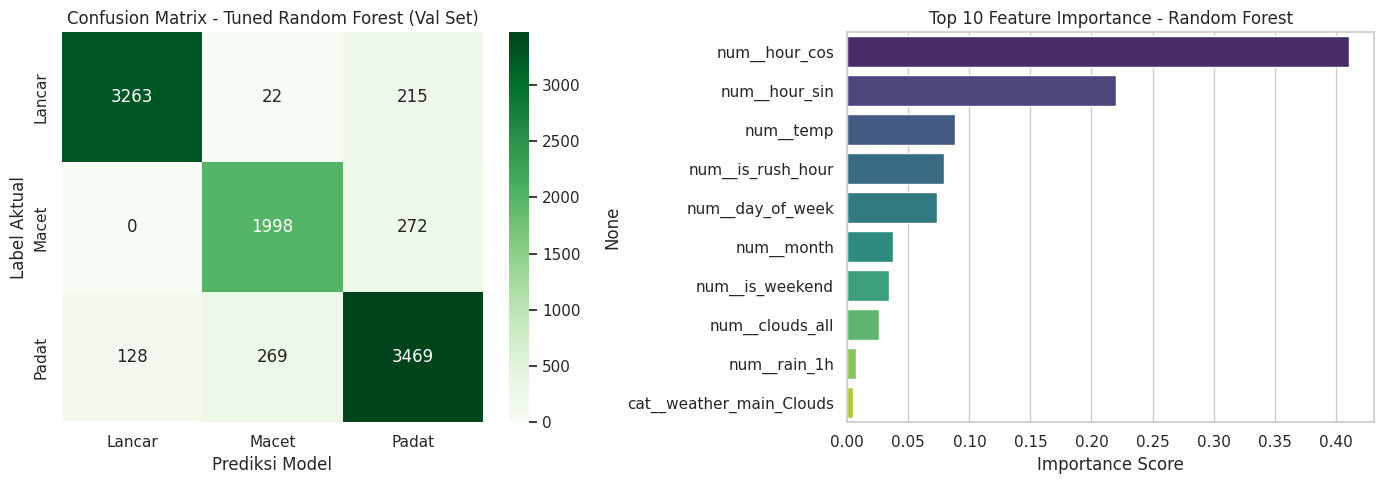

Model advanced tersimpan di ../models/advanced_rf.joblib


In [5]:
# 4. Evaluasi Validation Set, Confusion Matrix & Feature Importance
print("=== Classification Report (Validation Set - Tuned Random Forest) ===")
print(classification_report(y_val, val_pred_tuned, target_names=class_names))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_val, val_pred_tuned)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix - Tuned Random Forest (Val Set)")
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Label Aktual")

# Top 10 Feature Importances
importances = pd.Series(model_advanced.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Feature Importance - Random Forest")
axes[1].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()

# Simpan model advanced terbaik
os.makedirs("../models", exist_ok=True)
joblib.dump(model_advanced, "../models/advanced_rf.joblib")
print("Model advanced tersimpan di ../models/advanced_rf.joblib")